In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/parking_sessions.csv")

**Parking Duration Analysis**

Investigate how long vehicles remain parked.

In [4]:
eda_df = df.copy()

eda_df["duration_hours"] = eda_df["duration_seconds"] / 3600
eda_df["duration_hours"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)


count    271706.000000
mean          1.353104
std           6.167269
min         -16.994868
25%           0.228800
50%           0.956099
75%           1.705941
90%           2.577260
95%           3.410537
99%           9.701713
max        1224.301184
Name: duration_hours, dtype: float64

Text(0, 0.5, 'Number of Sessions')

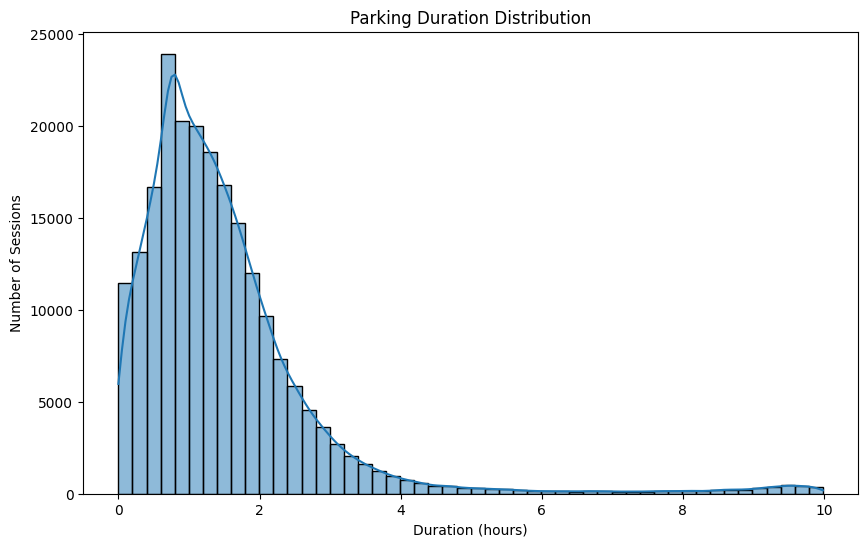

In [11]:
positive_duration = eda_df.loc[eda_df["duration_seconds"] > 0, "duration_hours"]

upper_limit = positive_duration.quantile(0.99)
plt.figure(figsize=(10, 6))
sns.histplot(positive_duration[positive_duration <= upper_limit],bins=50,kde=True)

plt.title("Parking Duration Distribution")
plt.xlabel("Duration (hours)")
plt.ylabel("Number of Sessions")

**Vehicle arrival patterns by hour**

C:\Users\ASUS\AppData\Local\Temp\ipykernel_5836\3547411918.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hourly_arrivals.index, y=hourly_arrivals.values, palette="viridis")


Text(0, 0.5, ' Total Number of Arrivals')

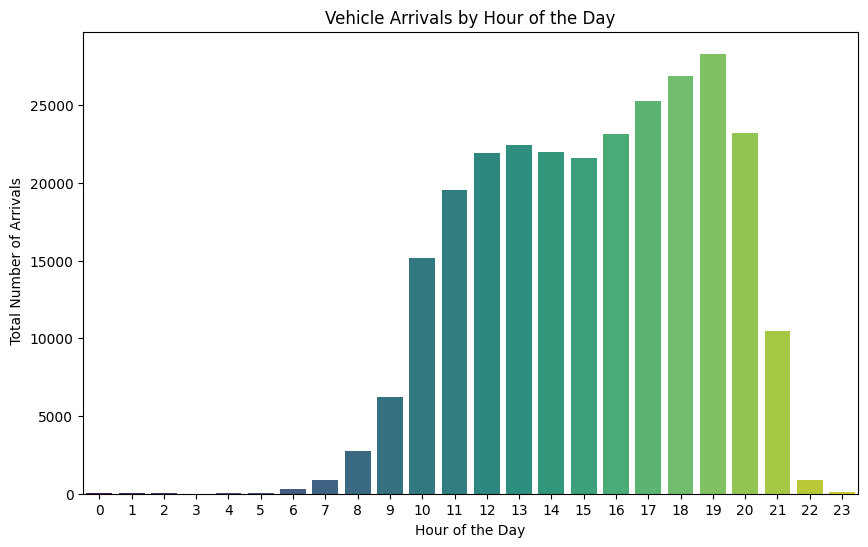

In [16]:
time_df = eda_df[eda_df["is_valid_timestamp"] == True].copy()
time_df["entry_time"] = pd.to_datetime(time_df["entry_time"])
time_df["entry_hour"] = time_df["entry_time"].dt.hour

hourly_arrivals = (time_df.groupby("entry_hour").size().reindex(range(24),fill_value=0))

hourly_arrivals
plt.figure(figsize=(10, 6))
sns.barplot(x=hourly_arrivals.index, y=hourly_arrivals.values, palette="viridis")
plt.title('Vehicle Arrivals by Hour of the Day')
plt.xlabel('Hour of the Day')
plt.ylabel(' Total Number of Arrivals')
